# skin 집계방식 비교 — 전체 feature(2,273차원) + B라벨 + Extra Trees 확장판

**배경**: `skin_aggregation_comparison.ipynb`에서 8개 공통 descriptor만으로 wmean/top/max/min 4가지 집계방식을 비교했더니, `min`(성분들 중 최솟값 — 즉 가장 "나쁜 쪽" 신호를 보존하는 방식)이 wmean(기존 production 방식, 함량 가중평균) 대비 PR-AUC를 크게 올렸음(0.131 → 0.297).

이 노트북은 같은 가설("혼합물의 자극성은 최악 성분 하나가 지배할 수 있다")을 **production이 실제로 쓰는 전체 feature(공통8 + RDKit descriptor 217 + Morgan FP 2048 = 2,273차원)** 로, **그리고 사람1 실험에서 확인된 현재 최고 조합(Skin B라벨 + Extra Trees)** 으로 재검증합니다.

| 항목 | 이전 노트북 | 이 노트북 |
|---|---|---|
| feature | 공통 descriptor 8개 | 공통8 + desc_217 + fp_w_2048 = 2,273개 |
| label | A(EPA 1·2→양성) | A, B(EPA 1·2·3→양성) 둘 다 비교 |
| 모델 | RandomForest만 | Extra Trees(주) + RandomForest(참고용) |
| 대상 | 원본 544개 제형 | 동일(원본 544개 — 이유는 아래) |

**스코프 제한(중요)**: 집계방식 비교는 제형별 "성분 구성비(%)" 원자료가 있어야 가능한데, 이 원자료(`skin_filtered.csv`)는 원본 NTP ICE 544개 제형에만 존재합니다. production의 662행(원본544+증강118)에서 쓰는 `skin_vectorized.csv`는 이미 집계가 끝난 결과물이라, 증강 118개 제형은 집계방식을 바꿔서 재계산할 원자료 자체가 없습니다. 따라서 이 비교는 원본 544개 한정이며, 사람1 보고서의 662행 기준 수치와는 모집단이 다릅니다(아래 2단계에서 wmean 결과를 production과 직접 대조해 파이프라인 정합성만 검증합니다).

## 0단계 — 데이터 로드

In [1]:
import numpy as np
import pandas as pd

BASE = r"C:\Users\UserK\학술제\skin irritation"

# 성분 단위 원자료(함량%, casrn 등) — 원본 544개 제형만 존재
filt = pd.read_csv(rf"{BASE}\skin_filtered.csv")
# 제형 단위 라벨(EPA 4등급 final_label, comp_group_id)
labels = pd.read_csv(rf"{BASE}\skin_formulation_level_with_comp_group.csv")
# 성분(casrn) 단위 전체 feature: 공통8 + desc_217 + fp_w_2048 = 2,273개
desc_full = pd.read_csv(rf"{BASE}\casrn_descriptors_full.csv").set_index("casrn")
FEATURE_COLS = list(desc_full.columns)
print("전체 feature 차원:", len(FEATURE_COLS))
print("desc_full에 등록된 고유 CASRN 수:", len(desc_full))

known = filt.dropna(subset=["casrn"]).copy()
known = known.drop_duplicates(subset=["formulation_id", "casrn"], keep="first")
known["has_descriptor"] = known["casrn"].isin(desc_full.index)

print("고유 제형 수:", known["formulation_id"].nunique())
print("제형당 성분 수 분포:")
print(known.groupby("formulation_id")["casrn"].nunique().value_counts().sort_index())
print("성분 CASRN 중 feature 보유 비율:", known["has_descriptor"].mean().round(4))

print()
print("final_label 분포:")
print(labels["final_label"].value_counts().sort_index())

전체 feature 차원: 2273
desc_full에 등록된 고유 CASRN 수: 346
고유 제형 수: 544
제형당 성분 수 분포:
casrn
1    334
2    129
3     53
4     23
5      3
6      1
7      1
Name: count, dtype: int64
성분 CASRN 중 feature 보유 비율: 0.9885

final_label 분포:
final_label
1     19
2     11
3     71
4    443
Name: count, dtype: int64


## 1단계 — 집계 함수 정의 (이전 노트북과 동일한 함수, 입력 feature 폭만 8 → 2,273로 확장)

`aggregate_group`은 feature가 스칼라 descriptor든 Morgan FP 비트(0/1)든 축 하나하나에 독립적으로 wmean/top/max/min을 적용하는 범용 함수라, **코드 변경 없이 그대로 재사용**됩니다. 다만 의미는 feature 종류에 따라 달라집니다:
- descriptor(연속값) 축에서 `max`/`min` → "축마다 다른 성분에서 값을 고른" franken-vector
- Morgan FP(0/1) 축에서 `max` = 비트별 OR("이 부분구조를 가진 성분이 하나라도 있으면 1") / `min` = 비트별 AND("모든 성분이 공통으로 가진 부분구조만 1") — 이쪽은 franken-vector가 아니라 실제로 의미가 분명한 집합연산입니다.

In [2]:
def aggregate_group(g_resolved, method):
    """g_resolved: has_descriptor==True인 성분 행들(한 제형분). method별 feature 벡터 반환."""
    d = desc_full.loc[g_resolved["casrn"]].values
    pct = g_resolved["percent_active_ingredient"].fillna(1.0).values
    if pct.sum() == 0:
        pct = np.ones_like(pct)

    if method == "wmean":
        return (pct[:, None] * d).sum(axis=0) / pct.sum()
    elif method == "top":
        idx = int(np.argmax(pct))
        return d[idx]
    elif method == "max":
        return d.max(axis=0)
    elif method == "min":
        return d.min(axis=0)
    else:
        raise ValueError(method)


def build_final(method):
    rows = []
    for fid, grp in known.groupby("formulation_id"):
        g_resolved = grp[grp["has_descriptor"]]
        row = {"formulation_id": fid}
        if len(g_resolved) > 0:
            vec = aggregate_group(g_resolved, method)
            for col, val in zip(FEATURE_COLS, vec):
                row[col] = val
        else:
            for col in FEATURE_COLS:
                row[col] = np.nan
        rows.append(row)
    agg = pd.DataFrame(rows)
    comp_count = known.groupby("formulation_id")["casrn"].nunique().rename("comp_count").reset_index()
    out = agg.merge(comp_count, on="formulation_id", how="left")
    out = out.merge(
        labels[["formulation_id", "final_label", "comp_group_id"]],
        on="formulation_id", how="left", validate="one_to_one",
    )
    out["binary_label_A"] = out["final_label"].map(lambda x: 1 if x in (1, 2) else 0)
    out["binary_label_B"] = out["final_label"].map(lambda x: 1 if x in (1, 2, 3) else 0)
    return out


METHODS = ["wmean", "top", "max", "min"]
finals = {m: build_final(m) for m in METHODS}
print("생성 완료:", {m: finals[m].shape for m in METHODS})

multi = finals["wmean"]["comp_count"] > 1
print("다성분 제형 수(방식 차이가 발생하는 곳):", int(multi.sum()), "/", len(finals["wmean"]))
for m in ["top", "max", "min"]:
    same = np.allclose(
        finals["wmean"].loc[~multi, FEATURE_COLS].values,
        finals[m].loc[~multi, FEATURE_COLS].values,
        equal_nan=True,
    )
    print(f"단일성분 제형에서 wmean과 완전히 동일한가({m}, True여야 정상):", same)

생성 완료: {'wmean': (544, 2279), 'top': (544, 2279), 'max': (544, 2279), 'min': (544, 2279)}
다성분 제형 수(방식 차이가 발생하는 곳): 210 / 544
단일성분 제형에서 wmean과 완전히 동일한가(top, True여야 정상): True
단일성분 제형에서 wmean과 완전히 동일한가(max, True여야 정상): True
단일성분 제형에서 wmean과 완전히 동일한가(min, True여야 정상): True


## 2단계 — 정합성 검증: wmean 집계 결과가 production `skin_vectorized.csv`와 일치하는가

이 노트북에서 새로 계산한 `wmean` 버전이, production이 실제로 쓰고 있는 값과 (원본 544개 범위 내에서) 같은 값을 내는지 직접 대조합니다. 다르면 이후 비교 자체가 무의미하므로, 추측하지 않고 직접 확인합니다.

In [3]:
vec = pd.read_csv(rf"{BASE}\skin_vectorized.csv", low_memory=False)
vec_orig = vec[~vec["formulation_id"].astype(str).str.startswith("AUG_")].copy()
print("production 원본(비증강) 행 수:", len(vec_orig))

common_cols = [c for c in FEATURE_COLS if c in vec_orig.columns]
print("대조 가능한 feature 컬럼 수:", len(common_cols), "/", len(FEATURE_COLS))

merged = finals["wmean"][["formulation_id"] + common_cols].merge(
    vec_orig[["formulation_id"] + common_cols], on="formulation_id", suffixes=("_nb", "_prod")
)
print("대조 가능한 제형 수:", len(merged))

diffs = []
for c in common_cols:
    a = merged[f"{c}_nb"].values
    b = merged[f"{c}_prod"].values
    ok = np.allclose(a, b, equal_nan=True, atol=1e-6)
    if not ok:
        diffs.append(c)

print("불일치 컬럼 수:", len(diffs))
if diffs:
    print("불일치 컬럼 예시(최대 10개):", diffs[:10])
else:
    print("전체 feature 컬럼이 production과 1e-6 오차 이내로 일치 — 파이프라인 정합성 확인 완료.")

production 원본(비증강) 행 수: 544
대조 가능한 feature 컬럼 수: 2273 / 2273
대조 가능한 제형 수: 544


불일치 컬럼 수: 0
전체 feature 컬럼이 production과 1e-6 오차 이내로 일치 — 파이프라인 정합성 확인 완료.


## 3단계 — 평가: Extra Trees(주) + RandomForest(참고) × wmean/top/max/min × label A/B

이전 노트북과 같은 설계(StratifiedGroupKFold 5-fold × 5 seed, `comp_group_id` 기준 그룹분할로 누수 방지). 추가로 **MCC·Sensitivity·Specificity(threshold=0.5 고정, 임계값 튜닝 없음)** 도 같이 봅니다 — ROC-AUC/PR-AUC만으로 좋다/나쁘다를 판단하지 않는다는 이번 프로젝트의 읽기 원칙을 그대로 따릅니다.

In [4]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef, confusion_matrix

MODELS = {
    "ExtraTrees": lambda seed: ExtraTreesClassifier(
        n_estimators=500, class_weight="balanced", min_samples_leaf=2, n_jobs=-1, random_state=seed
    ),
    "RandomForest": lambda seed: RandomForestClassifier(
        n_estimators=500, class_weight="balanced_subsample", min_samples_leaf=2, n_jobs=-1, random_state=seed
    ),
}


def grouped_cv(df, feature_cols, label_col, model_name, n_splits=5, seeds=range(5)):
    ok = df[feature_cols].notna().all(axis=1).values
    X = df.loc[ok, feature_cols].values
    y = df.loc[ok, label_col].values
    g = df.loc[ok, "comp_group_id"].astype(str).values

    rows = []
    for s in seeds:
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=s)
        oof = np.zeros(len(y))
        for tr, te in cv.split(X, y, g):
            assert set(g[tr]).isdisjoint(g[te]), "그룹 누수 발생"
            m = MODELS[model_name](s).fit(X[tr], y[tr])
            oof[te] = m.predict_proba(X[te])[:, 1]
        pred05 = (oof >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred05).ravel()
        rows.append({
            "seed": s,
            "roc_auc": roc_auc_score(y, oof),
            "pr_auc": average_precision_score(y, oof),
            "mcc": matthews_corrcoef(y, pred05),
            "sensitivity": tp / (tp + fn) if (tp + fn) > 0 else np.nan,
            "specificity": tn / (tn + fp) if (tn + fp) > 0 else np.nan,
        })
    return pd.DataFrame(rows), int(ok.sum()), int(y.sum())


results = []
per_seed = {}
for label_name, label_col in [("A", "binary_label_A"), ("B", "binary_label_B")]:
    for model_name in MODELS:
        for m in METHODS:
            r, n_used, n_pos = grouped_cv(finals[m], FEATURE_COLS, label_col, model_name)
            key = (label_name, model_name, m)
            per_seed[key] = r
            results.append({
                "label": label_name, "model": model_name, "method": m,
                "n_used": n_used, "n_pos": n_pos,
                "roc_auc_mean": r.roc_auc.mean(), "roc_auc_std": r.roc_auc.std(),
                "pr_auc_mean": r.pr_auc.mean(), "pr_auc_std": r.pr_auc.std(),
                "mcc_mean": r.mcc.mean(), "mcc_std": r.mcc.std(),
                "sensitivity_mean": r.sensitivity.mean(), "specificity_mean": r.specificity.mean(),
            })
            print(f"완료: label={label_name} model={model_name} method={m}")

result_table = pd.DataFrame(results)
result_table

완료: label=A model=ExtraTrees method=wmean


완료: label=A model=ExtraTrees method=top


완료: label=A model=ExtraTrees method=max


완료: label=A model=ExtraTrees method=min


완료: label=A model=RandomForest method=wmean


완료: label=A model=RandomForest method=top


... (7 outputs left out)

완료: label=B model=RandomForest method=top


완료: label=B model=RandomForest method=max


완료: label=B model=RandomForest method=min


,label,model,method,n_used,n_pos,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,mcc_mean,mcc_std,sensitivity_mean,specificity_mean
0,A,ExtraTrees,wmean,541,30,0.753229,0.022899,0.221117,0.035045,0.169681,0.027855,0.273333,0.929941
1,A,ExtraTrees,top,541,30,0.743301,0.018252,0.267108,0.044525,0.130724,0.019856,0.273333,0.903327
2,A,ExtraTrees,max,541,30,0.720770,0.013973,0.264375,0.037349,0.154346,0.018451,0.266667,0.923679
3,A,ExtraTrees,min,541,30,0.761898,0.026790,0.287735,0.048709,0.213142,0.011528,0.333333,0.927984
4,A,RandomForest,wmean,541,30,0.733307,0.023452,0.210785,0.037660,0.250566,0.034646,0.213333,0.978865
5,A,RandomForest,top,541,30,0.735408,0.019761,0.246740,0.036299,0.206097,0.049248,0.240000,0.959687
6,A,RandomForest,max,541,30,0.704651,0.016664,0.263949,0.035059,0.204843,0.044972,0.180000,0.977299
7,A,RandomForest,min,541,30,0.757058,0.021687,0.351628,0.044343,0.321933,0.041680,0.300000,0.975342
8,B,ExtraTrees,wmean,541,99,0.712834,0.008621,0.379399,0.014837,0.220579,0.027307,0.385859,0.842081
9,B,ExtraTrees,top,541,99,0.714317,0.004436,0.379844,0.022130,0.260103,0.037540,0.490909,0.801357


## 4단계 — 결과 표 (label·model별로 정리, PR-AUC 내림차순)

In [5]:
pd.set_option("display.width", 140)
for label_name in ["A", "B"]:
    for model_name in MODELS:
        sub = result_table[(result_table.label == label_name) & (result_table.model == model_name)]
        sub = sub.sort_values("pr_auc_mean", ascending=False)
        print(f"=== label {label_name} / {model_name} ===")
        display_cols = ["method", "n_used", "n_pos", "roc_auc_mean", "roc_auc_std",
                         "pr_auc_mean", "pr_auc_std", "mcc_mean", "mcc_std",
                         "sensitivity_mean", "specificity_mean"]
        print(sub[display_cols].round(3).to_string(index=False))
        print()

=== label A / ExtraTrees ===
method  n_used  n_pos  roc_auc_mean  roc_auc_std  pr_auc_mean  pr_auc_std  mcc_mean  mcc_std  sensitivity_mean  specificity_mean
   min     541     30         0.762        0.027        0.288       0.049     0.213    0.012             0.333             0.928
   top     541     30         0.743        0.018        0.267       0.045     0.131    0.020             0.273             0.903
   max     541     30         0.721        0.014        0.264       0.037     0.154    0.018             0.267             0.924
 wmean     541     30         0.753        0.023        0.221       0.035     0.170    0.028             0.273             0.930

=== label A / RandomForest ===
method  n_used  n_pos  roc_auc_mean  roc_auc_std  pr_auc_mean  pr_auc_std  mcc_mean  mcc_std  sensitivity_mean  specificity_mean
   min     541     30         0.757        0.022        0.352       0.044     0.322    0.042             0.300             0.975
   max     541     30         0.705 

## 5단계 — 시각화

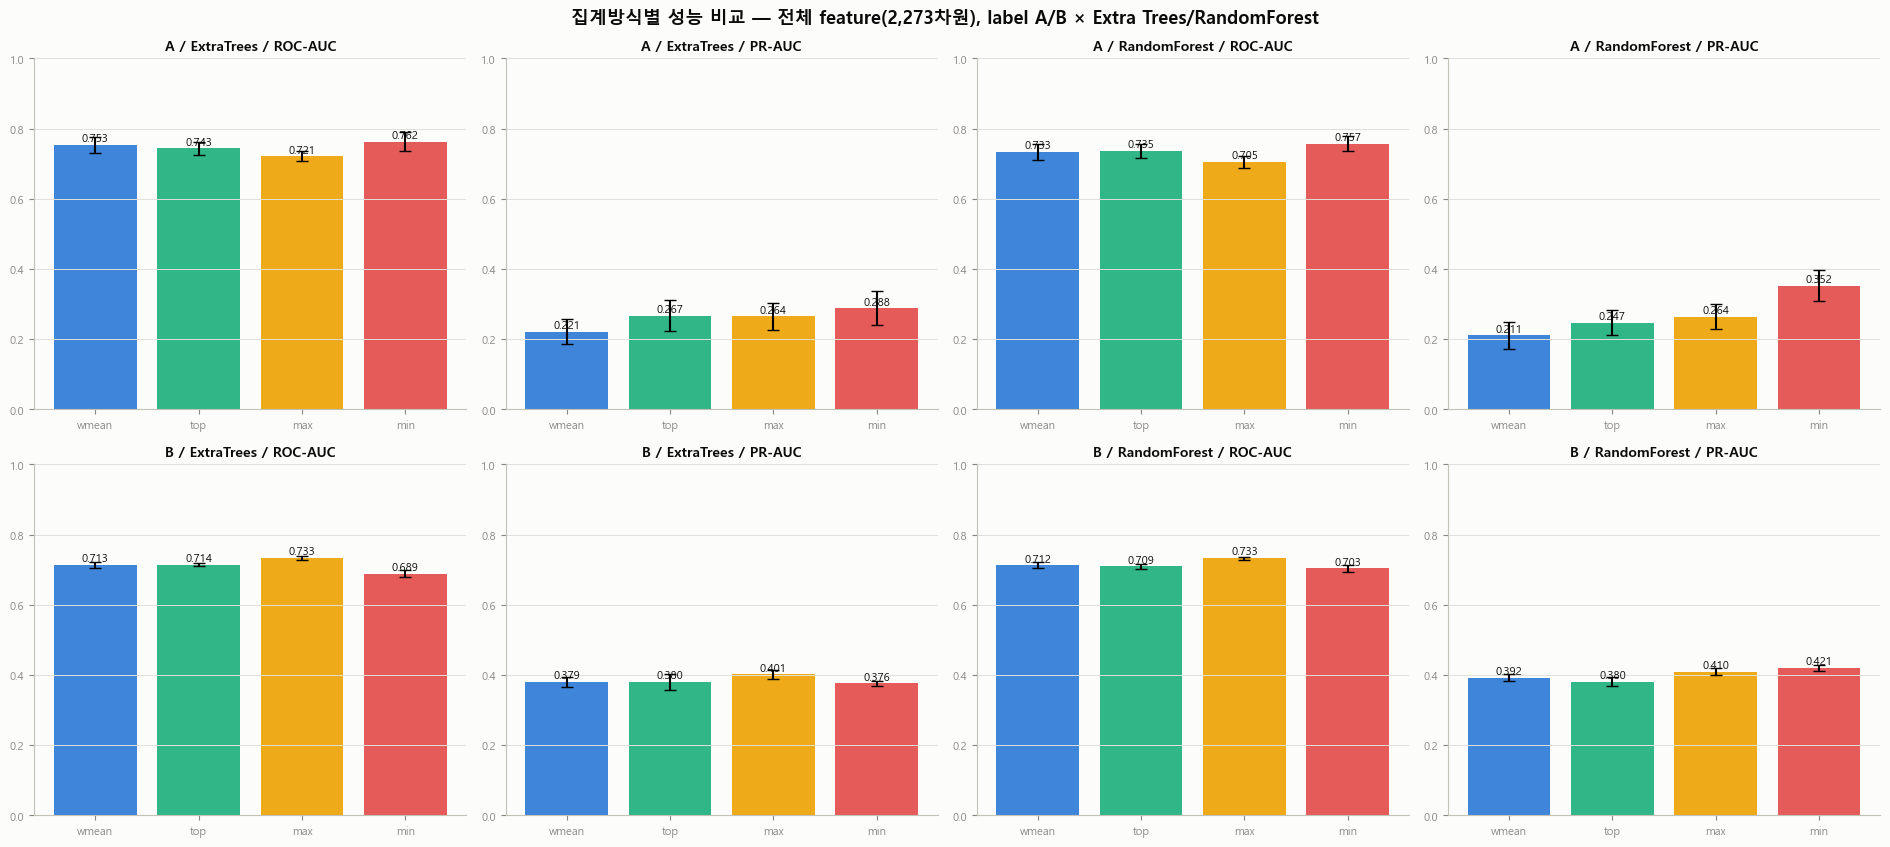

In [6]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

_font_path = r"C:\Windows\Fonts\malgun.ttf"
fm.fontManager.addfont(_font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=_font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

SURFACE = "#fcfcfb"; INK = "#0b0b0b"; MUTED = "#898781"; GRID_C = "#e1e0d9"; BASE_C = "#c3c2b7"
COLORS = {"wmean": "#2a78d6", "top": "#1baf7a", "max": "#eda100", "min": "#e34948"}

fig, axes = plt.subplots(2, 4, figsize=(19, 8.6), facecolor=SURFACE)

idx = 0
for label_name in ["A", "B"]:
    for model_name in MODELS:
        for metric, title in [("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC")]:
            ax = axes.flat[idx]
            ax.set_facecolor(SURFACE)
            means, stds = [], []
            for m in METHODS:
                r = per_seed[(label_name, model_name, m)]
                means.append(r[metric].mean())
                stds.append(r[metric].std())
            bars = ax.bar(METHODS, means, yerr=stds, capsize=4,
                          color=[COLORS[m] for m in METHODS], alpha=0.9)
            for b, mean in zip(bars, means):
                ax.text(b.get_x() + b.get_width() / 2, mean + 0.01, f"{mean:.3f}",
                        ha="center", fontsize=8, color=INK)
            ax.set_title(f"{label_name} / {model_name} / {title}", fontsize=10, color=INK, fontweight="bold")
            ax.tick_params(colors=MUTED, labelsize=8)
            ax.set_ylim(0, 1.0)
            for s in ["top", "right"]:
                ax.spines[s].set_visible(False)
            ax.spines["left"].set_color(BASE_C)
            ax.spines["bottom"].set_color(BASE_C)
            ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)
            idx += 1

fig.suptitle("집계방식별 성능 비교 — 전체 feature(2,273차원), label A/B × Extra Trees/RandomForest",
             fontsize=13, color=INK, fontweight="bold")
plt.tight_layout()
plt.savefig(rf"{BASE}\skin_aggregation_full_features_comparison.png", dpi=150, facecolor=SURFACE)
plt.show()

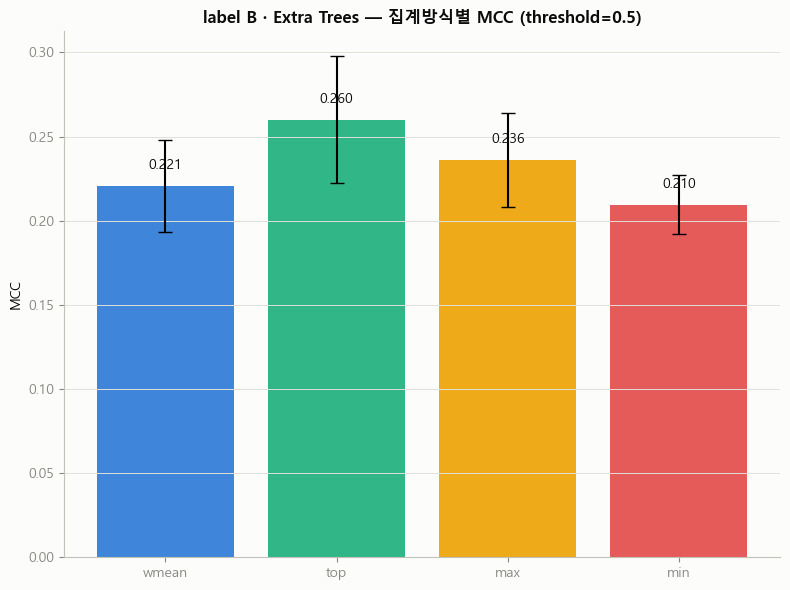

In [7]:
fig2, ax = plt.subplots(1, 1, figsize=(8, 6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
r_b_et = {m: per_seed[("B", "ExtraTrees", m)] for m in METHODS}
means = [r_b_et[m].mcc.mean() for m in METHODS]
stds = [r_b_et[m].mcc.std() for m in METHODS]
bars = ax.bar(METHODS, means, yerr=stds, capsize=5, color=[COLORS[m] for m in METHODS], alpha=0.9)
for b, mean in zip(bars, means):
    ax.text(b.get_x() + b.get_width() / 2, mean + 0.01, f"{mean:.3f}", ha="center", fontsize=10, color=INK)
ax.set_title("label B · Extra Trees — 집계방식별 MCC (threshold=0.5)", fontsize=12, color=INK, fontweight="bold")
ax.set_ylabel("MCC")
ax.tick_params(colors=MUTED)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.spines["left"].set_color(BASE_C)
ax.spines["bottom"].set_color(BASE_C)
ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)
plt.tight_layout()
plt.savefig(rf"{BASE}\skin_aggregation_full_features_B_extratrees_mcc.png", dpi=150, facecolor=SURFACE)
plt.show()

## 6단계 — 결론 (수치는 위 계산 결과에서 그대로 가져옴, 하드코딩 없음)

In [8]:
summary_target = result_table[(result_table.label == "B") & (result_table.model == "ExtraTrees")].copy()
summary_target = summary_target.sort_values("mcc_mean", ascending=False)
best = summary_target.iloc[0]
wmean_row = summary_target[summary_target.method == "wmean"].iloc[0]

print("label B / Extra Trees 기준")
print(f"MCC 1위: {best['method']} (MCC {best['mcc_mean']:.3f} ± {best['mcc_std']:.3f})")
print(f"wmean(기존 production 방식): MCC {wmean_row['mcc_mean']:.3f} ± {wmean_row['mcc_std']:.3f}")
print(f"차이: {best['mcc_mean'] - wmean_row['mcc_mean']:+.3f} (wmean의 std {wmean_row['mcc_std']:.3f}와 비교해서 판단)")
print()

gap = best['mcc_mean'] - wmean_row['mcc_mean']
noise = max(best['mcc_std'], wmean_row['mcc_std'])
if best['method'] == "wmean":
    print("→ 이 조합(B+ExtraTrees)에서는 기존 wmean 방식이 그대로 최선으로 나왔습니다.")
elif gap > noise:
    print(f"→ {best['method']} 방식이 fold-seed 변동폭보다 크게 wmean을 앞섰습니다 — 집계방식 교체가 유의미할 가능성이 있습니다.")
else:
    print(f"→ {best['method']} 방식이 평균은 높지만 그 차이({gap:.3f})가 fold-seed 변동폭({noise:.3f}) 안에 들어와, 통계적으로 확실하다고 보기는 이릅니다.")

print()
print("다른 label·model 조합 전체 1위 방식:")
print(result_table.loc[result_table.groupby(["label", "model"])["mcc_mean"].idxmax(),
                        ["label", "model", "method", "mcc_mean", "mcc_std"]].to_string(index=False))

label B / Extra Trees 기준
MCC 1위: top (MCC 0.260 ± 0.038)
wmean(기존 production 방식): MCC 0.221 ± 0.027
차이: +0.040 (wmean의 std 0.027와 비교해서 판단)

→ top 방식이 fold-seed 변동폭보다 크게 wmean을 앞섰습니다 — 집계방식 교체가 유의미할 가능성이 있습니다.

다른 label·model 조합 전체 1위 방식:
label        model method  mcc_mean  mcc_std
    A   ExtraTrees    min  0.213142 0.011528
    A RandomForest    min  0.321933 0.041680
    B   ExtraTrees    top  0.260103 0.037540
    B RandomForest    top  0.248802 0.031035


## 한계점

1. **스코프**: 이 비교는 원본 NTP ICE 544개 제형에서만 수행했습니다(성분 구성비 원자료가 이 범위에만 존재). production이 실제로 학습에 쓰는 662행(증강 118개 포함)과는 모집단이 다르므로, 여기서 확인된 방식을 바로 production에 적용하려면 증강 데이터의 성분 구성비 원자료부터 확보하거나, 증강 파이프라인 자체를 해당 집계방식으로 다시 돌려야 합니다.
2. **threshold=0.5 고정**: MCC·Sensitivity·Specificity는 임계값을 튜닝하지 않은 0.5 기준입니다. 사람1의 production 보고서는 내부 OOF로 임계값을 따로 선택했으므로, 여기 수치를 그 보고서의 수치와 절대값으로 직접 비교하지 마십시오(같은 feature·같은 분할이라도 임계값 선택방식이 다르면 Sensitivity/Specificity/MCC가 달라집니다). ROC-AUC/PR-AUC는 임계값과 무관하므로 비교적 안전하게 비교 가능합니다.
3. **max/min franken-vector 문제**: descriptor(연속값) 축에서는 여전히 유효합니다 — 축마다 다른 성분에서 값을 뽑아오므로 실재하지 않는 조합일 수 있습니다. 반면 Morgan FP(이진) 축에서는 max=OR("부분구조 존재 여부"), min=AND("공통 부분구조")로 해석이 분명해, 이 부분은 franken-vector 우려에서 비교적 자유롭습니다.
4. **다성분 제형은 544건 중 210건(39%)뿐**이라 표본이 제한적이고, 그중 양성 라벨은 더 적습니다. 차이가 fold-seed 변동폭 안에 들어오면 통계적으로 유의미하다고 단정하기 어렵습니다.
5. 이 실험은 skin만 대상입니다. eye는 다성분 비율이나 결과 양상이 다를 수 있습니다.

---

# 7단계 — 두 집계방식을 concat한 feature 테스트

지금까지 결과: label A는 `min`이, label B는 `top`이 wmean보다 뚜렷이 좋았습니다. 그렇다면 **두 표현을 이어붙이면(concat) 단일 방식보다 더 나을까?**를 확인합니다.

방법: 같은 제형에 대해 방식1의 2,273개 feature와 방식2의 2,273개 feature를 옆으로 이어붙여 4,546차원 feature를 만듭니다(모델이 두 "관점"을 동시에 보고 알아서 가중치를 배우게 하는 방식 — 사람이 미리 섞는 비율을 정하지 않습니다). 가능한 6개 조합(wmean+top, wmean+min, wmean+max, top+min, top+max, min+max) 전부를 label A/B × Extra Trees/RandomForest로 평가합니다.

In [9]:
from itertools import combinations

PAIRS = list(combinations(METHODS, 2))
print("테스트할 조합:", PAIRS)


def build_concat(m1, m2):
    a = finals[m1][["formulation_id", "comp_group_id", "comp_count",
                     "binary_label_A", "binary_label_B"] + FEATURE_COLS].copy()
    b = finals[m2][["formulation_id"] + FEATURE_COLS].copy()
    a = a.rename(columns={c: f"{m1}__{c}" for c in FEATURE_COLS})
    b = b.rename(columns={c: f"{m2}__{c}" for c in FEATURE_COLS})
    return a.merge(b, on="formulation_id")


concat_finals = {}
concat_feature_cols = {}
for m1, m2 in PAIRS:
    df = build_concat(m1, m2)
    concat_finals[(m1, m2)] = df
    concat_feature_cols[(m1, m2)] = [f"{m1}__{c}" for c in FEATURE_COLS] + [f"{m2}__{c}" for c in FEATURE_COLS]
    print(f"{m1}+{m2}: feature 차원 {len(concat_feature_cols[(m1, m2)])}, 행수 {df.shape[0]}")

테스트할 조합: [('wmean', 'top'), ('wmean', 'max'), ('wmean', 'min'), ('top', 'max'), ('top', 'min'), ('max', 'min')]
wmean+top: feature 차원 4546, 행수 544
wmean+max: feature 차원 4546, 행수 544
wmean+min: feature 차원 4546, 행수 544
top+max: feature 차원 4546, 행수 544
top+min: feature 차원 4546, 행수 544
max+min: feature 차원 4546, 행수 544


In [10]:
concat_results = []
concat_per_seed = {}
for label_name, label_col in [("A", "binary_label_A"), ("B", "binary_label_B")]:
    for model_name in MODELS:
        for (m1, m2) in PAIRS:
            df = concat_finals[(m1, m2)]
            fcols = concat_feature_cols[(m1, m2)]
            r, n_used, n_pos = grouped_cv(df, fcols, label_col, model_name)
            pair_name = f"{m1}+{m2}"
            concat_per_seed[(label_name, model_name, pair_name)] = r
            concat_results.append({
                "label": label_name, "model": model_name, "method": pair_name,
                "n_used": n_used, "n_pos": n_pos,
                "roc_auc_mean": r.roc_auc.mean(), "roc_auc_std": r.roc_auc.std(),
                "pr_auc_mean": r.pr_auc.mean(), "pr_auc_std": r.pr_auc.std(),
                "mcc_mean": r.mcc.mean(), "mcc_std": r.mcc.std(),
                "sensitivity_mean": r.sensitivity.mean(), "specificity_mean": r.specificity.mean(),
            })
            print(f"완료(concat): label={label_name} model={model_name} pair={pair_name}")

concat_table = pd.DataFrame(concat_results)
concat_table.sort_values(["label", "model", "mcc_mean"], ascending=[True, True, False])

완료(concat): label=A model=ExtraTrees pair=wmean+top


완료(concat): label=A model=ExtraTrees pair=wmean+max


완료(concat): label=A model=ExtraTrees pair=wmean+min


완료(concat): label=A model=ExtraTrees pair=top+max


완료(concat): label=A model=ExtraTrees pair=top+min


완료(concat): label=A model=ExtraTrees pair=max+min


... (15 outputs left out)

완료(concat): label=B model=RandomForest pair=top+max


완료(concat): label=B model=RandomForest pair=top+min


완료(concat): label=B model=RandomForest pair=max+min


,label,model,method,n_used,n_pos,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,mcc_mean,mcc_std,sensitivity_mean,specificity_mean
2,A,ExtraTrees,wmean+min,541,30,0.760483,0.023015,0.251725,0.034143,0.183726,0.031014,0.286667,0.931898
5,A,ExtraTrees,max+min,541,30,0.752955,0.028102,0.279749,0.034527,0.174361,0.024267,0.280000,0.929550
4,A,ExtraTrees,top+min,541,30,0.755297,0.026933,0.286646,0.043438,0.169756,0.018838,0.273333,0.929941
1,A,ExtraTrees,wmean+max,541,30,0.738317,0.019249,0.245149,0.043792,0.167609,0.024200,0.273333,0.928767
0,A,ExtraTrees,wmean+top,541,30,0.745695,0.021249,0.232908,0.050809,0.159251,0.026843,0.273333,0.923679
3,A,ExtraTrees,top+max,541,30,0.746954,0.023064,0.264938,0.037804,0.157542,0.016454,0.266667,0.925636
10,A,RandomForest,top+min,541,30,0.755838,0.019505,0.311788,0.046379,0.317468,0.040351,0.273333,0.979648
8,A,RandomForest,wmean+min,541,30,0.755395,0.025850,0.289745,0.057146,0.313250,0.039633,0.273333,0.978865
11,A,RandomForest,max+min,541,30,0.747019,0.026126,0.308934,0.044971,0.299298,0.035118,0.273333,0.976125
6,A,RandomForest,wmean+top,541,30,0.734149,0.027739,0.242266,0.055367,0.246786,0.057388,0.213333,0.978474


## 8단계 — 단일방식 최고기록 vs concat 최고기록 직접 비교

같은 label·model 안에서, 지금까지 나온 단일방식(wmean/top/max/min) 중 최고 MCC와, 이번 concat 6조합 중 최고 MCC를 나란히 놓고 봅니다.

In [11]:
combined_rows = []
for label_name in ["A", "B"]:
    for model_name in MODELS:
        single_sub = result_table[(result_table.label == label_name) & (result_table.model == model_name)]
        single_best = single_sub.loc[single_sub["mcc_mean"].idxmax()]

        concat_sub = concat_table[(concat_table.label == label_name) & (concat_table.model == model_name)]
        concat_best = concat_sub.loc[concat_sub["mcc_mean"].idxmax()]

        combined_rows.append({
            "label": label_name, "model": model_name,
            "단일방식_1위": single_best["method"], "단일_MCC": round(single_best["mcc_mean"], 3),
            "단일_MCC_std": round(single_best["mcc_std"], 3),
            "concat_1위": concat_best["method"], "concat_MCC": round(concat_best["mcc_mean"], 3),
            "concat_MCC_std": round(concat_best["mcc_std"], 3),
            "차이(concat-단일)": round(concat_best["mcc_mean"] - single_best["mcc_mean"], 3),
        })

comparison_df = pd.DataFrame(combined_rows)
comparison_df

,label,model,단일방식_1위,단일_MCC,단일_MCC_std,concat_1위,concat_MCC,concat_MCC_std,차이(concat-단일)
0,A,ExtraTrees,min,0.213,0.012,wmean+min,0.184,0.031,-0.029
1,A,RandomForest,min,0.322,0.042,top+min,0.317,0.040,-0.004
2,B,ExtraTrees,top,0.260,0.038,max+min,0.222,0.027,-0.038
3,B,RandomForest,top,0.249,0.031,top+min,0.241,0.032,-0.008


## 9단계 — concat 결과 시각화 (label B / Extra Trees — 실제 팀 목표 조합 중심)

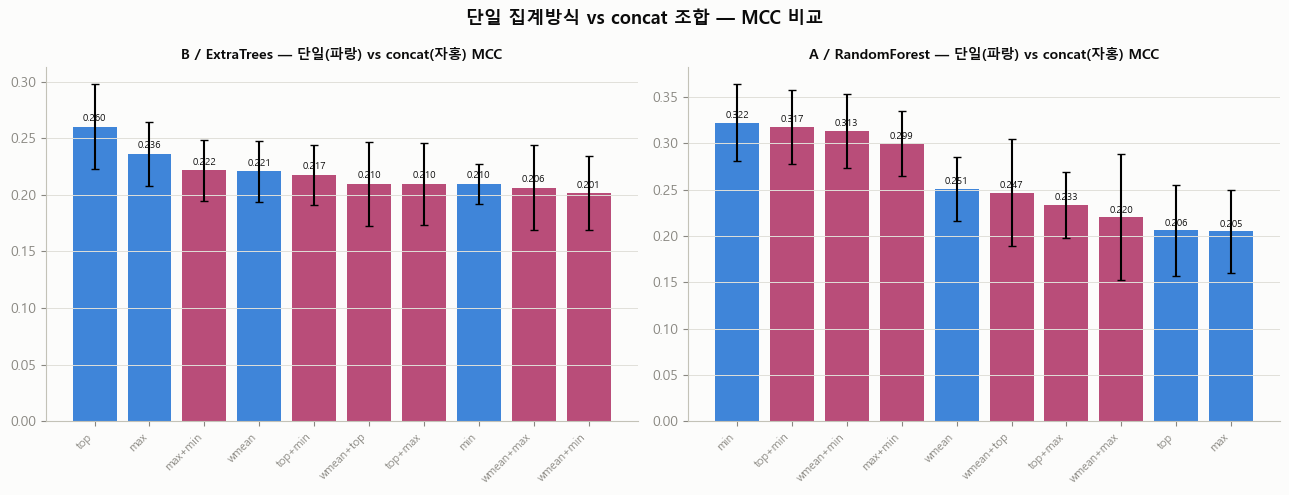

In [12]:
fig3, axes3 = plt.subplots(1, 2, figsize=(13, 5), facecolor=SURFACE)

for ax, label_name, model_name in zip(axes3, ["B", "A"], ["ExtraTrees", "RandomForest"]):
    ax.set_facecolor(SURFACE)
    single_sub = result_table[(result_table.label == label_name) & (result_table.model == model_name)]
    concat_sub = concat_table[(concat_table.label == label_name) & (concat_table.model == model_name)]

    names = list(single_sub["method"]) + list(concat_sub["method"])
    means = list(single_sub["mcc_mean"]) + list(concat_sub["mcc_mean"])
    stds = list(single_sub["mcc_std"]) + list(concat_sub["mcc_std"])
    is_concat = [False] * len(single_sub) + [True] * len(concat_sub)
    colors = ["#2a78d6" if not c else "#b23a6b" for c in is_concat]

    order = np.argsort(means)[::-1]
    names = [names[i] for i in order]
    means = [means[i] for i in order]
    stds = [stds[i] for i in order]
    colors = [colors[i] for i in order]

    bars = ax.bar(range(len(names)), means, yerr=stds, capsize=3, color=colors, alpha=0.9)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
    for b, mean in zip(bars, means):
        ax.text(b.get_x() + b.get_width() / 2, mean + 0.005, f"{mean:.3f}", ha="center", fontsize=7, color=INK)
    ax.set_title(f"{label_name} / {model_name} — 단일(파랑) vs concat(자홍) MCC", fontsize=10, color=INK, fontweight="bold")
    ax.tick_params(colors=MUTED)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(BASE_C)
    ax.spines["bottom"].set_color(BASE_C)
    ax.grid(axis="y", color=GRID_C, linewidth=0.7, zorder=0)

fig3.suptitle("단일 집계방식 vs concat 조합 — MCC 비교", fontsize=13, color=INK, fontweight="bold")
plt.tight_layout()
plt.savefig(rf"{BASE}\skin_aggregation_concat_vs_single_mcc.png", dpi=150, facecolor=SURFACE)
plt.show()

## 10단계 — concat 결론 (수치는 위 계산 결과에서 그대로 가져옴)

In [13]:
target_label, target_model = "B", "ExtraTrees"
row = comparison_df[(comparison_df.label == target_label) & (comparison_df.model == target_model)].iloc[0]
print(f"목표 조합: label {target_label} / {target_model}")
print(f"단일방식 1위: {row['단일방식_1위']} (MCC {row['단일_MCC']} ± {row['단일_MCC_std']})")
print(f"concat 1위: {row['concat_1위']} (MCC {row['concat_MCC']} ± {row['concat_MCC_std']})")
print(f"차이: {row['차이(concat-단일)']:+.3f}")

noise = max(row["단일_MCC_std"], row["concat_MCC_std"])
if row["차이(concat-단일)"] > noise:
    print(f"\n→ concat이 fold-seed 변동폭({noise:.3f})보다 크게 단일방식을 앞섰습니다 — concat 표현이 유의미하게 나을 가능성이 있습니다.")
elif row["차이(concat-단일)"] > 0:
    print(f"\n→ concat이 평균은 높지만 차이({row['차이(concat-단일)']:.3f})가 변동폭({noise:.3f}) 안에 들어와, 확실한 개선이라 보기 이릅니다.")
else:
    print("\n→ concat이 단일방식보다 나아지지 않았습니다. feature 차원만 2배로 늘려 과적합 위험만 커졌을 가능성을 함께 고려해야 합니다.")

print()
print("전체 조합별 1위(단일 vs concat) 요약:")
comparison_df

목표 조합: label B / ExtraTrees
단일방식 1위: top (MCC 0.26 ± 0.038)
concat 1위: max+min (MCC 0.222 ± 0.027)
차이: -0.038

→ concat이 단일방식보다 나아지지 않았습니다. feature 차원만 2배로 늘려 과적합 위험만 커졌을 가능성을 함께 고려해야 합니다.

전체 조합별 1위(단일 vs concat) 요약:


,label,model,단일방식_1위,단일_MCC,단일_MCC_std,concat_1위,concat_MCC,concat_MCC_std,차이(concat-단일)
0,A,ExtraTrees,min,0.213,0.012,wmean+min,0.184,0.031,-0.029
1,A,RandomForest,min,0.322,0.042,top+min,0.317,0.040,-0.004
2,B,ExtraTrees,top,0.260,0.038,max+min,0.222,0.027,-0.038
3,B,RandomForest,top,0.249,0.031,top+min,0.241,0.032,-0.008


## 한계점 (concat 실험 추가분)

1. **feature 차원이 2배(4,546)로 늘었는데 표본(541건)은 그대로**라, 두 표현을 합쳐서 더 잘 맞는 게 아니라 단순히 과적합 여지가 커져서 train 성능만 좋아 보일 위험이 있습니다. 반드시 OOF(held-out) 지표로만 판단해야 하며(이 노트북은 그렇게 했습니다), 그래도 해석은 보수적으로 해야 합니다.
2. 6개 조합을 전부 다중비교했으므로, 이 중 가장 좋아 보이는 하나를 "진짜 최고"라고 확정하기보다는 다음 단계(예: 독립적인 반복 실험, 또는 198건 증강 데이터까지 확장한 뒤 재검증)에서 한 번 더 재현되는지 확인하는 게 안전합니다.
3. concat은 "두 관점을 모델이 알아서 가중"하는 방식이라 해석(어떤 성분이 왜 그 판정에 기여했는지)이 단일 방식보다 어려워집니다 — 성능이 좋아도 설명력은 떨어질 수 있습니다.